# Building Age Classification from Satellite Imagery

# Notebook 7.Ensemble + Spatial Smoothing + Self-Training

---

Notebook 5 built transfer-oriented features and a two-stage LightGBM. This notebook adds four steps on top. **Each step follows from a finding in our EDA**, and each is reported as an ablation so its contribution is visible.

| Step | What | Why (evidence) |
|---|---|---|
| **1. LightGBM + RandomForest ensemble** | Average the probabilities of Notebook 5's continued-boosting model and a RandomForest trained on Madrid + the Amsterdam support pixels | In our model comparison RF was the strongest single learner, especially at small *n*. Bagging (RF) and boosting (LightGBM) make different errors, so averaging reduces variance |
| **2. Spatial smoothing** | Blend each pixel's class probabilities with the mean of its neighbours | Building age is spatially clustered: neighbours share the class **76% (Madrid) / 87% (Amsterdam)** of the time vs ~27% by chance (Notebook 5 §5.5). Radius and strength are **tuned on Madrid only** |
| **3. Label clamping** | Before smoothing, the *n* labelled pixels are set to their known class | Their labels are known, so they spread to their neighbours (a simple form of label propagation) |
| **4. Self-training** | Pseudo-label the most confident unlabelled Amsterdam pixels (balanced per class), refit both models once, then ensemble + smooth again | Amsterdam imagery is plentiful; only labels are scarce. Smoothed predictions give cleaner pseudo-labels |

### Rules we keep
* Amsterdam **labels** are used only through the *n* support pixels of each draw. Pseudo-labels are model predictions, not true labels.
* Every setting is **fixed in advance or tuned on Madrid**. Nothing is tuned on Amsterdam query labels.
* **Identical support draws** to Notebooks 5 and 6, so the comparison is paired and fair.

## 7.1 Setup

Run from the repository root. Notebook 5's feature cache (`data/cache/features_*.parquet`) and the saved Madrid LightGBM (`models/stage1_madrid_classifier.txt`) if present; otherwise it builds them.

**Runtime:** the RandomForest is refitted on Madrid + Amsterdam support for every draw (twice with self-training). That is about 100 RF fits; Lower `RF_PARAMS['n_estimators']` for a quicker run.

In [1]:
"""Shared helpers for Notebook 5: memory-light loading of the Landsat parquet files.

Each city is loaded into a dense "cube" of shape (n_pixels, n_years, n_bands) instead of
a 3M-row DataFrame. String columns (pixel_id, scene_id_N, dataset_N) are never read, which
keeps peak memory well under 2 GB on an 8 GB machine.
"""
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

BANDS = ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']
YEARS = np.arange(1984, 2026)
BLUE_MAX = 15_000          # haze threshold from Notebook 2
CLASS_EVENTS = {'Amsterdam': 1945, 'Madrid': 1960}
FILES = {'Madrid': 'madrid_train.parquet', 'Amsterdam': 'amsterdam_data.parquet'}


def find_data_dir():
    return next(p for p in [Path('data'), Path('./data')]
                if (p / 'madrid_train.parquet').exists())


def age_class(year, city):
    """Bin weighted_mean_year into classes 1-4 with the city-specific 1/2 boundary."""
    bins = [-np.inf, CLASS_EVENTS[city], 1984, 2004, np.inf]
    return pd.cut(year, bins=bins, labels=[1, 2, 3, 4]).astype(int)


def load_cube(city, data_dir=None, cache=True):
    """Return a dict with the per-pixel annual reflectance cube and pixel metadata.

    cube[i, t, b]  median of the QA-valid, haze-free observations of pixel i in year YEARS[t]
                   for band b (NaN if no valid observation that year).
    n_obs[i, t]    number of valid observations that went into the median (0-3).
    doy[i, t]      mean day-of-year of those observations.
    """
    data_dir = Path(data_dir) if data_dir else find_data_dir()
    cache_path = data_dir / 'cache' / f'cube_{city}.npz'
    if cache and cache_path.exists():
        z = np.load(cache_path)
        out = {k: z[k] for k in z.files}
        out['city'] = city
        return out

    cols = ['year', 'px_key', 'py_key', 'pixel_x', 'pixel_y', 'coverage', 'weighted_mean_year']
    for s in (1, 2, 3):
        cols += [f'{b}_{s}' for b in BANDS] + [f'qa_valid_{s}', f'doy_{s}']
    t = pq.read_table(data_dir / FILES[city], columns=cols)

    px = t['px_key'].to_numpy(); py = t['py_key'].to_numpy()
    keys = px.astype(np.int64) * 1_000_000 + py
    ukeys, pix_idx = np.unique(keys, return_inverse=True)
    yr_idx = t['year'].to_numpy() - YEARS[0]
    n_pix, n_yr = len(ukeys), len(YEARS)

    # Stack the 3 observation slots: (rows, 3, bands)
    obs = np.stack([np.stack([t[f'{b}_{s}'].to_numpy(zero_copy_only=False).astype(np.float32)
                              for b in BANDS], axis=1) for s in (1, 2, 3)], axis=1)
    valid = np.stack([t[f'qa_valid_{s}'].to_numpy(zero_copy_only=False) for s in (1, 2, 3)], axis=1)
    valid = np.nan_to_num(valid.astype(float), nan=0).astype(bool)
    valid &= np.isfinite(obs).all(axis=2)
    valid &= (obs > 0).all(axis=2) & (obs < 65535).all(axis=2)   # corrupt zero / saturated
    valid &= obs[:, :, 0] <= BLUE_MAX                             # haze
    obs[~valid] = np.nan
    doy = np.stack([t[f'doy_{s}'].to_numpy(zero_copy_only=False).astype(np.float32)
                    for s in (1, 2, 3)], axis=1)
    doy[~valid] = np.nan

    with np.errstate(all='ignore'):
        med = np.nanmedian(obs, axis=1)            # (rows, bands)
        mdoy = np.nanmean(doy, axis=1)
    cube = np.full((n_pix, n_yr, len(BANDS)), np.nan, dtype=np.float32)
    cube[pix_idx, yr_idx] = med
    n_obs = np.zeros((n_pix, n_yr), dtype=np.int8)
    n_obs[pix_idx, yr_idx] = valid.sum(axis=1)
    doy_c = np.full((n_pix, n_yr), np.nan, dtype=np.float32)
    doy_c[pix_idx, yr_idx] = mdoy

    # Per-pixel constants (first occurrence)
    first = np.unique(pix_idx, return_index=True)[1]
    out = dict(
        cube=cube, n_obs=n_obs, doy=doy_c,
        px=px[first].astype(np.int32), py=py[first].astype(np.int32),
        x=t['pixel_x'].to_numpy()[first].astype(np.float64),
        y=t['pixel_y'].to_numpy()[first].astype(np.float64),
        coverage=t['coverage'].to_numpy()[first].astype(np.float32),
        wmy=t['weighted_mean_year'].to_numpy()[first].astype(np.float32),
    )
    if cache:
        cache_path.parent.mkdir(exist_ok=True)
        np.savez_compressed(cache_path, **out)
    out['city'] = city
    return out


# ════════════════════════════════════════════════════════════════════════════
# Time-series preparation
# ════════════════════════════════════════════════════════════════════════════
INDICES = ['NDVI', 'NDBI', 'UI', 'MNDWI', 'BSI']


def fill_gaps(cube):
    """Linear interpolation along the year axis; edges take the nearest observed value."""
    c = cube.copy()
    n_pix, n_yr, n_b = c.shape
    t = np.arange(n_yr)
    valid = np.isfinite(c[:, :, 0])
    prev = np.where(valid, t, -1); prev = np.maximum.accumulate(prev, axis=1)
    nxt = np.where(valid, t, n_yr); nxt = np.minimum.accumulate(nxt[:, ::-1], axis=1)[:, ::-1]
    prev_c = np.where(prev < 0, nxt, prev); nxt_c = np.where(nxt >= n_yr, prev_c, nxt)
    rows = np.arange(n_pix)[:, None]
    lo, hi = c[rows, prev_c], c[rows, nxt_c]
    w = np.where(nxt_c > prev_c, (t - prev_c) / np.maximum(nxt_c - prev_c, 1), 0.0)[:, :, None]
    filled = lo + w * (hi - lo)
    return np.where(valid[:, :, None], c, filled).astype(np.float32)


def add_indices(cube):
    """Append the 5 normalised-difference indices as extra channels."""
    B, G, R, N, S1, S2 = [cube[:, :, i] for i in range(6)]
    nd = lambda a, b: (a - b) / (a + b + 1e-6)
    idx = np.stack([nd(N, R), nd(S1, N), nd(S2, N), nd(G, S1),
                    nd(S1 + R, N + B)], axis=2)
    return np.concatenate([cube, idx.astype(np.float32)], axis=2)


def city_year_anomaly(series):
    """Express every value relative to the city in the same year:
    (x - median over pixels) / IQR over pixels, per year and channel.
    Removes city-wide offsets (climate, materials, atmosphere, sensor) and keeps
    the within-city ranking, which is the part that transfers between cities."""
    med = np.nanmedian(series, axis=0, keepdims=True)
    q75, q25 = np.nanpercentile(series, [75, 25], axis=0, keepdims=True)
    return ((series - med) / (q75 - q25 + 1e-6)).astype(np.float32)


# ════════════════════════════════════════════════════════════════════════════
# Per-pixel feature engineering
# ════════════════════════════════════════════════════════════════════════════
CHANNELS = BANDS + INDICES
PERIODS = [(1984, 1991), (1992, 1999), (2000, 2007), (2008, 2015), (2016, 2025)]


def _slope(s):
    t = np.arange(s.shape[1], dtype=np.float32); t -= t.mean()
    return (s * t[None, :, None]).sum(1) / (t ** 2).sum()


def breakpoint_features(s, min_seg=3):
    """Best single change-point per pixel, scanned over every split year.

    For each split k the score is the squared difference between the mean after and
    before k, summed over channels and weighted by the segment sizes (a CUSUM / two-
    segment fit). Returns the break year, its strength, and the per-channel jump."""
    n_pix, T, C = s.shape
    cs = np.cumsum(s, axis=1)
    total = cs[:, -1:, :]
    ks = np.arange(min_seg, T - min_seg + 1)
    best_score = np.full(n_pix, -np.inf, dtype=np.float32)
    best_k = np.zeros(n_pix, dtype=np.int32)
    best_jump = np.zeros((n_pix, C), dtype=np.float32)
    for k in ks:
        before = cs[:, k - 1, :] / k
        after = (total[:, 0, :] - cs[:, k - 1, :]) / (T - k)
        jump = after - before
        score = (k * (T - k) / T) * (jump ** 2).sum(1)
        better = score > best_score
        best_score[better] = score[better]; best_k[better] = k
        best_jump[better] = jump[better]
    return YEARS[best_k].astype(np.float32), np.sqrt(best_score), best_jump


def pixel_features(series, prefix=''):
    """Collapse a (pixels, years, channels) series into a per-pixel feature table."""
    f = {}
    yrs = YEARS
    mean, std = series.mean(1), series.std(1)
    slope = _slope(series)
    early = series[:, yrs <= 2003].mean(1); late = series[:, yrs >= 2004].mean(1)
    d = np.diff(series, axis=1)
    for j, ch in enumerate(CHANNELS):
        f[f'{ch}_mean'] = mean[:, j]; f[f'{ch}_std'] = std[:, j]
        f[f'{ch}_slope'] = slope[:, j]
        f[f'{ch}_late_minus_early'] = late[:, j] - early[:, j]
        f[f'{ch}_dstd'] = d[:, :, j].std(1)
        f[f'{ch}_dmaxabs'] = np.abs(d[:, :, j]).max(1)
        for a, b in PERIODS:
            f[f'{ch}_p{a}'] = series[:, (yrs >= a) & (yrs <= b), j].mean(1)
    # Change-point on all channels jointly (smoothed with a 3-yr running mean first)
    k = np.ones(3) / 3
    smooth = np.apply_along_axis(lambda v: np.convolve(v, k, mode='same'), 1, series)
    smooth[:, 0] = series[:, 0]; smooth[:, -1] = series[:, -1]
    byear, bstrength, bjump = breakpoint_features(smooth)
    f['break_year'] = byear; f['break_strength'] = bstrength
    for j, ch in enumerate(CHANNELS):
        f[f'{ch}_break_jump'] = bjump[:, j]
    # Year of the largest year-on-year change in the overall spectral vector
    dnorm = np.sqrt((np.diff(smooth, axis=1) ** 2).sum(2))
    f['maxjump_year'] = YEARS[1:][dnorm.argmax(1)].astype(np.float32)
    f['maxjump_size'] = dnorm.max(1)
    # Stability before / after 2004 (pre-1984 buildings stay stable in both)
    f['std_early'] = series[:, yrs <= 2003].std(1).mean(1)
    f['std_late'] = series[:, yrs >= 2004].std(1).mean(1)
    return pd.DataFrame({prefix + k: v for k, v in f.items()})


def spatial_context(feat, px, py, cols, radii=(2, 5)):
    """Neighbourhood means of selected features over building pixels within a square
    window of radius r grid cells (r=2 -> 150 m, r=5 -> 330 m). Building age is spatially
    clustered (whole neighbourhoods are built together), so context carries signal."""
    from scipy.ndimage import uniform_filter
    gx, gy = px - px.min(), py - py.min()
    H, W = gy.max() + 1, gx.max() + 1
    mask = np.zeros((H, W), np.float32); mask[gy, gx] = 1
    out = {}
    for r in radii:
        size = 2 * r + 1
        cnt = uniform_filter(mask, size, mode='constant')
        out[f'ctx{r}_density'] = cnt[gy, gx]
        for c in cols:
            g = np.zeros((H, W), np.float32); g[gy, gx] = feat[c].values
            out[f'ctx{r}_{c}'] = (uniform_filter(g, size, mode='constant') / np.maximum(cnt, 1e-6))[gy, gx]
    return pd.DataFrame(out)


def build_features(d, context_cols=None):
    """Full feature table for one city cube (city-relative, transfer-oriented)."""
    series = add_indices(fill_gaps(d['cube']))
    anom = city_year_anomaly(series)
    feat = pixel_features(anom)
    if context_cols is None:
        context_cols = [c for c in feat.columns
                        if c.endswith('_mean') or c in ('break_year', 'break_strength')]
    ctx = spatial_context(feat, d['px'], d['py'], context_cols)
    return pd.concat([feat, ctx], axis=1)


def spatial_blocks(px, py, block_m=1000):
    """Group id of the square block (default 1 km) each pixel falls in. Used for spatial
    cross-validation so neighbouring pixels never sit on both sides of a split."""
    cells = int(round(block_m / 30))
    bx, by = (px - px.min()) // cells, (py - py.min()) // cells
    return (bx.astype(np.int64) * 100_000 + by).astype(np.int64)


def build_raw_features(d):
    """Absolute-reflectance features in the style of Notebook 3 (for comparison)."""
    series = add_indices(fill_gaps(d['cube']))
    return pixel_features(series)


In [2]:
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.ndimage import uniform_filter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold


warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='X does not have valid feature names')
plt.rcParams['figure.dpi'] = 100

# ── Config ────────────────────────────────────────────────────────────────────
SEED      = 42
SHOTS     = [5, 25, 50, 100, 200]          # labelled Amsterdam pixels per class
N_TRIALS  = 10                             # random support draws per shot size (same draws as Notebook 5)
N_JOBS    = os.cpu_count()

# Stage 1 LightGBM (identical to Notebook 5)
STAGE1_PARAMS = dict(n_estimators=400, learning_rate=0.05, num_leaves=63, subsample=0.8,
                     subsample_freq=1, colsample_bytree=0.5, class_weight='balanced',
                     n_jobs=N_JOBS, verbose=-1, random_state=SEED)
# RandomForest (Madrid + weighted Amsterdam support)
RF_PARAMS = dict(n_estimators=300, max_features='sqrt', min_samples_leaf=2, max_samples=0.5,
                 n_jobs=N_JOBS, random_state=SEED)
RF_K      = 25                             # Amsterdam support gets a share n / (n + RF_K) of the total weight

# Spatial smoothing: grid searched on Madrid out-of-fold predictions (no Amsterdam labels)
SMOOTH_RADII = [1, 2, 3]                   # window radius in pixels (1 = 3x3 = 90 m)
SMOOTH_BETAS = [0.0, 0.25, 0.5, 0.75, 1.0] # weight of the neighbourhood mean

# Self-training (fixed in advance)
PSEUDO_MULT   = 4                          # pseudo-labels per class = min(PSEUDO_MULT * n, PSEUDO_MAX)
PSEUDO_MAX    = 400
PSEUDO_WEIGHT = 0.5                        # a pseudo-label counts half as much as a true label

DATA_DIR    = find_data_dir()
CACHE_DIR   = DATA_DIR / 'cache';  CACHE_DIR.mkdir(exist_ok=True)
MODEL_DIR   = Path('models');      MODEL_DIR.mkdir(exist_ok=True)
RESULTS_DIR = Path('results');     RESULTS_DIR.mkdir(exist_ok=True)
CITIES      = ['Madrid', 'Amsterdam']
print('Data folder:', DATA_DIR.resolve(), '| threads:', N_JOBS)

Data folder: /home/participant-d5/Building_Age_Classification/data | threads: 16


In [3]:
t0 = time.time()
DATA = {c: load_cube(c, DATA_DIR) for c in CITIES}
Y    = {c: age_class(DATA[c]['wmy'], c) for c in CITIES}


def load_features(city):
    # Reuse Notebook 5's cache when it exists (same columns, same order).
    path = CACHE_DIR / f'features_{city}.parquet'
    if path.exists():
        return pd.read_parquet(path)
    feat = build_features(DATA[city])
    feat.to_parquet(path)
    return feat


def city_scale(df):
    # Robust z-score of every feature against its own city (unsupervised, no labels used).
    return (df - df.median()) / (df.quantile(.75) - df.quantile(.25) + 1e-9)


FEAT = {c: load_features(c) for c in CITIES}
X    = {c: city_scale(FEAT[c]).values.astype(np.float32) for c in CITIES}
Xm, ym = X['Madrid'], Y['Madrid']
Xa, ya = X['Amsterdam'], Y['Amsterdam']
Xm_rf, Xa_rf = np.nan_to_num(Xm), np.nan_to_num(Xa)          # RandomForest input without NaN
print(f'Inputs ready in {time.time() - t0:.0f}s   Madrid {Xm.shape}   Amsterdam {Xa.shape}')

Inputs ready in 2s   Madrid (76263, 166)   Amsterdam (25992, 166)


---
## 7.2 Spatial smoothing, tuned on Madrid

Every pixel sits on the 30 m Landsat grid. For a window of radius *r* we compute the mean class probability over the **building pixels** in the window (empty cells are ignored), then blend:

$$P^{\text{smooth}}_i = (1-\beta)\,P_i + \beta\,\overline{P}_{\text{window}(i)}$$

To choose *r* and β **without touching Amsterdam labels**, we take out-of-fold Madrid predictions from a **spatial-block** cross-validation (whole 1 km blocks held out, so each prediction comes from a model that never saw that neighbourhood) and pick the (*r*, β) with the best Madrid macro-F1.

Madrid is *less* clustered than Amsterdam (76% vs 87%), so a setting chosen on Madrid is, if anything, conservative for Amsterdam.

In [4]:
def make_grid(d):
    gx, gy = d['px'] - d['px'].min(), d['py'] - d['py'].min()
    return gx, gy, (gy.max() + 1, gx.max() + 1)


GRID = {c: make_grid(DATA[c]) for c in CITIES}


def smooth(P, city, radius, beta):
    # Blend each pixel's probabilities with the mean over building pixels in a (2r+1)^2 window.
    if beta == 0:
        return P
    gx, gy, shape = GRID[city]
    size = 2 * radius + 1
    mask = np.zeros(shape, np.float32); mask[gy, gx] = 1
    cnt = uniform_filter(mask, size, mode='constant')[gy, gx]
    neigh = np.empty_like(P)
    for k in range(P.shape[1]):
        g = np.zeros(shape, np.float32); g[gy, gx] = P[:, k]
        neigh[:, k] = uniform_filter(g, size, mode='constant')[gy, gx] / np.maximum(cnt, 1e-6)
    return (1 - beta) * P + beta * neigh


# Out-of-fold Madrid probabilities from spatial-block CV (same LightGBM settings as Stage 1)
t0 = time.time()
blocks = spatial_blocks(DATA['Madrid']['px'], DATA['Madrid']['py'])
oof = np.zeros((len(ym), 4))
for k, (tr, va) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(Xm, ym, blocks), 1):
    oof[va] = lgb.LGBMClassifier(**STAGE1_PARAMS).fit(Xm[tr], ym[tr]).predict_proba(Xm[va])
    print(f'  fold {k} done ({time.time() - t0:.0f}s)')

grid = pd.DataFrame({f'r = {r}': [f1_score(ym, smooth(oof, 'Madrid', r, b).argmax(1) + 1, average='macro')
                                  for b in SMOOTH_BETAS] for r in SMOOTH_RADII},
                    index=[f'beta = {b}' for b in SMOOTH_BETAS])
display(grid.round(4))
best = grid.stack().idxmax()
SMOOTH_R = int(best[1].split('= ')[1]); SMOOTH_B = float(best[0].split('= ')[1])
print(f'Chosen on Madrid: radius {SMOOTH_R}, beta {SMOOTH_B}  ->  Madrid spatial-CV F1 '
      f'{grid.iloc[0, 0]:.3f} (no smoothing) -> {grid.values.max():.3f}')

  fold 1 done (13s)
  fold 2 done (27s)
  fold 3 done (40s)
  fold 4 done (53s)
  fold 5 done (66s)


,r = 1,r = 2,r = 3
beta = 0.0,0.6478,0.6478,0.6478
beta = 0.25,0.6517,0.6531,0.6531
beta = 0.5,0.6553,0.6570,0.6570
beta = 0.75,0.6549,0.6539,0.6514
beta = 1.0,0.6517,0.6427,0.6327


Chosen on Madrid: radius 3, beta 0.5  ->  Madrid spatial-CV F1 0.648 (no smoothing) -> 0.657


---
## 7.3 Stage 1 models and Stage 2 building blocks

* **LightGBM:** Notebook 5's Madrid classifier plus **continued boosting** on the Amsterdam samples (unchanged, except that it now accepts sample weights for pseudo-labels).
* **RandomForest:** refitted on **all of Madrid + the Amsterdam samples**. Madrid pixels are class-balanced. The Amsterdam samples together get a share `n / (n + RF_K)` of the total weight: about 17% at *n* = 5, 50% at *n* = 25 and 89% at *n* = 200. With few labels the forest relies on Madrid; with many it follows Amsterdam. This is the bagging counterpart of continued boosting.

In [5]:
STAGE1_LGB = MODEL_DIR / 'stage1_madrid_classifier.txt'
if STAGE1_LGB.exists():
    lgb_madrid = lgb.Booster(model_file=str(STAGE1_LGB))
else:
    lgb_madrid = lgb.LGBMClassifier(**STAGE1_PARAMS).fit(Xm, ym).booster_
    lgb_madrid.save_model(str(STAGE1_LGB))
assert lgb_madrid.num_feature() == Xa.shape[1], 'Feature mismatch with the saved LightGBM model'
LGB_RAW = lgb_madrid.predict(Xa, raw_score=True)                 # Madrid scores on Amsterdam

cnt_m = np.bincount(ym, minlength=5)[1:]
W_M = (len(ym) / (4 * cnt_m))[ym - 1]                            # class-balanced Madrid weights


def softmax(z):
    e = np.exp(z - z.max(1, keepdims=True))
    return e / e.sum(1, keepdims=True)


def fit_lgbm(idx, labels, weights, n_eff):
    # Continue boosting the Madrid classifier on Amsterdam pixels idx (Notebook 5, plus sample weights).
    params = dict(objective='multiclass', num_class=4, learning_rate=0.05, num_leaves=7,
                  min_data_in_leaf=max(3, int(n_eff) // 5), feature_fraction=0.5, lambda_l2=5.0,
                  num_threads=N_JOBS, seed=SEED, verbose=-1)
    ds = lgb.Dataset(Xa[idx], labels - 1, weight=weights, init_score=LGB_RAW[idx])
    booster = lgb.train(params, ds, num_boost_round=int(np.clip(n_eff, 10, 150)))
    return softmax(LGB_RAW + booster.predict(Xa, raw_score=True))


def fit_rf(idx, labels, weights, n_eff):
    # RandomForest on all of Madrid + Amsterdam pixels idx; Amsterdam share of weight = n / (n + RF_K).
    share = n_eff / (n_eff + RF_K)
    w_a = weights / weights.sum() * W_M.sum() * share / (1 - share)
    rf = RandomForestClassifier(**RF_PARAMS).fit(np.vstack([Xm_rf, Xa_rf[idx]]), np.r_[ym, labels],
                                                 sample_weight=np.r_[W_M, w_a])
    return rf.predict_proba(Xa_rf)


def clamp(P, sup):
    # Fix the labelled pixels to their known class (they then spread through the smoothing).
    P = P.copy(); P[sup] = np.eye(4)[ya[sup] - 1]
    return P


def pseudo_labels(P, sup, n):
    # Most confident unlabelled pixels, the same number per predicted class.
    m = min(PSEUDO_MULT * n, PSEUDO_MAX)
    pred, conf = P.argmax(1) + 1, P.max(1)
    free = np.ones(len(P), bool); free[sup] = False
    idx = [c[np.argsort(-conf[c])[:m]] for c in (np.where(free & (pred == k))[0] for k in range(1, 5))]
    idx = np.concatenate(idx)
    return idx, pred[idx]

In [6]:
# Zero-shot reference (no Amsterdam labels): Madrid LightGBM, Madrid RF, their ensemble, smoothed
t0 = time.time()
rf_madrid = RandomForestClassifier(**RF_PARAMS).fit(Xm_rf, ym, sample_weight=W_M)
P0 = {'lgbm': softmax(LGB_RAW), 'rf': rf_madrid.predict_proba(Xa_rf)}
P0['lgbm+rf'] = (P0['lgbm'] + P0['rf']) / 2
P0['lgbm+rf + smooth'] = smooth(P0['lgbm+rf'], 'Amsterdam', SMOOTH_R, SMOOTH_B)
ZERO_SHOT = {k: f1_score(ya, P.argmax(1) + 1, average='macro') for k, P in P0.items()}
display(pd.Series(ZERO_SHOT, name='Amsterdam zero-shot macro-F1').round(3).to_frame())
print(f'({time.time() - t0:.0f}s)   Notebook 5 LightGBM zero-shot: 0.530   Notebook 4 baseline: 0.343')

,Amsterdam zero-shot macro-F1
lgbm,0.530
rf,0.565
lgbm+rf,0.551
lgbm+rf + smooth,0.559


(13s)   Notebook 5 LightGBM zero-shot: 0.530   Notebook 4 baseline: 0.343


---
## 7.4 Few-shot evaluation (ablation)

For every draw we build the pipeline step by step and score each intermediate on **all non-support** Amsterdam pixels:

| Row | Adds |
|---|---|
| `lgbm (Notebook 5)` | Reference: Notebook 5's final model |
| `rf` | RandomForest alone |
| `lgbm+rf` | Step 1: ensemble |
| `lgbm + smooth` | Step 2-3 on LightGBM alone (isolates smoothing) |
| `lgbm+rf + smooth` | Steps 1-3 |
| **`FINAL: lgbm+rf + smooth + self-train`** | Steps 1-4 |

In [7]:
# Support draws: same generator, seed and loop order as Notebook 5, so the draws are identical
rng = np.random.default_rng(SEED)
DRAWS = {n: [np.concatenate([rng.choice(np.where(ya == c)[0], n, replace=False) for c in range(1, 5)])
             for _ in range(N_TRIALS)] for n in SHOTS}
REF, FINAL = 'lgbm (Notebook 5)', 'FINAL: lgbm+rf + smooth + self-train'


def run_pipeline(sup, n):
    # Returns {row name: probabilities for every Amsterdam pixel} and the pseudo-labels used.
    ys, ones = ya[sup], np.ones(len(sup))
    out = {}
    p_lgb = fit_lgbm(sup, ys, ones, n)
    p_rf = fit_rf(sup, ys, ones, n)
    p_ens = (p_lgb + p_rf) / 2
    out[REF], out['rf'], out['lgbm+rf'] = p_lgb, p_rf, p_ens
    out['lgbm + smooth'] = smooth(clamp(p_lgb, sup), 'Amsterdam', SMOOTH_R, SMOOTH_B)
    out['lgbm+rf + smooth'] = p_sm = smooth(clamp(p_ens, sup), 'Amsterdam', SMOOTH_R, SMOOTH_B)

    # Self-training: one round on confident, smoothed predictions
    pi, pl = pseudo_labels(p_sm, sup, n)
    idx, lab = np.r_[sup, pi], np.r_[ys, pl]
    w = np.r_[ones, np.full(len(pi), PSEUDO_WEIGHT)]
    n_eff = n + PSEUDO_WEIGHT * len(pi) / 4
    p_ens2 = (fit_lgbm(idx, lab, w, n_eff) + fit_rf(idx, lab, w, n_eff)) / 2
    out[FINAL] = smooth(clamp(p_ens2, sup), 'Amsterdam', SMOOTH_R, SMOOTH_B)
    return out, (pi, pl)


res, res_pc, pseudo_acc = {}, {}, {n: [] for n in SHOTS}
t0 = time.time()
for n in SHOTS:
    for sup in DRAWS[n]:
        q = np.ones(len(ya), bool); q[sup] = False
        out, (pi, pl) = run_pipeline(sup, n)
        pseudo_acc[n].append((ya[pi] == pl).mean())             # diagnostic only
        for row, P in out.items():
            pred = P[q].argmax(1) + 1
            res.setdefault(row, {k: [] for k in SHOTS})[n].append(f1_score(ya[q], pred, average='macro'))
            res_pc.setdefault(row, {k: [] for k in SHOTS})[n].append(
                f1_score(ya[q], pred, average=None, labels=[1, 2, 3, 4]))
    print(f'n = {n:3d}  ({time.time() - t0:.0f}s)   ' +
          '  '.join(f'{r.split(":")[0]}: {np.mean(res[r][n]):.3f}' for r in (REF, 'lgbm+rf + smooth', FINAL)) +
          f'   pseudo-label accuracy {np.mean(pseudo_acc[n]):.2f}')

n =   5  (272s)   lgbm (Notebook 5): 0.557  lgbm+rf + smooth: 0.588  FINAL: 0.613   pseudo-label accuracy 0.93
n =  25  (555s)   lgbm (Notebook 5): 0.650  lgbm+rf + smooth: 0.673  FINAL: 0.688   pseudo-label accuracy 0.97
n =  50  (856s)   lgbm (Notebook 5): 0.680  lgbm+rf + smooth: 0.697  FINAL: 0.704   pseudo-label accuracy 0.97
n = 100  (1190s)   lgbm (Notebook 5): 0.714  lgbm+rf + smooth: 0.729  FINAL: 0.731   pseudo-label accuracy 0.98
n = 200  (1547s)   lgbm (Notebook 5): 0.731  lgbm+rf + smooth: 0.748  FINAL: 0.746   pseudo-label accuracy 0.98


---
## 7.5 Results

In [8]:
BASELINE_NB4 = {5: 0.544, 25: 0.599, 50: 0.608, 100: 0.613, 200: 0.615}
ORDER = [REF, 'rf', 'lgbm+rf', 'lgbm + smooth', 'lgbm+rf + smooth', FINAL]

table = pd.DataFrame({f'n = {n}': [f'{np.mean(res[r][n]):.3f} ± {np.std(res[r][n]):.3f}' for r in ORDER]
                      for n in SHOTS}, index=ORDER)
table['Average F1'] = [f'{np.mean([np.mean(res[r][n]) for n in SHOTS]):.3f}' for r in ORDER]
table.loc['Notebook 4 baseline'] = [f'{BASELINE_NB4[n]:.3f}' for n in SHOTS] + [f'{np.mean(list(BASELINE_NB4.values())):.3f}']
display(table)

out = pd.DataFrame({r: [np.mean(res[r][n]) for n in SHOTS] + [np.std(res[r][n]) for n in SHOTS] for r in ORDER},
                   index=[f'mean_{n}' for n in SHOTS] + [f'std_{n}' for n in SHOTS]).T
out['average'] = out[[f'mean_{n}' for n in SHOTS]].mean(1)
out.to_csv(RESULTS_DIR / 'nb7_final_results.csv')
print('Saved', RESULTS_DIR / 'nb7_final_results.csv')
print(f"Prize view (FINAL): average {out.loc[FINAL, 'average']:.3f} | 25-shot {out.loc[FINAL, 'mean_25']:.3f} | "
      f"peak {out.loc[FINAL, [f'mean_{n}' for n in SHOTS]].max():.3f}")

,n = 5,n = 25,n = 50,n = 100,n = 200,Average F1
lgbm (Notebook 5),0.557 ± 0.012,0.650 ± 0.008,0.680 ± 0.010,0.714 ± 0.010,0.731 ± 0.006,0.666
rf,0.582 ± 0.005,0.623 ± 0.008,0.638 ± 0.007,0.667 ± 0.006,0.692 ± 0.005,0.640
lgbm+rf,0.575 ± 0.011,0.657 ± 0.008,0.684 ± 0.011,0.716 ± 0.009,0.734 ± 0.005,0.673
lgbm + smooth,0.574 ± 0.015,0.670 ± 0.007,0.697 ± 0.012,0.731 ± 0.009,0.748 ± 0.005,0.684
lgbm+rf + smooth,0.588 ± 0.014,0.673 ± 0.008,0.697 ± 0.013,0.729 ± 0.008,0.748 ± 0.005,0.687
FINAL: lgbm+rf + smooth + self-train,0.613 ± 0.009,0.688 ± 0.010,0.704 ± 0.013,0.731 ± 0.008,0.746 ± 0.005,0.696
Notebook 4 baseline,0.544,0.599,0.608,0.613,0.615,0.596


Saved results/nb7_final_results.csv
Prize view (FINAL): average 0.696 | 25-shot 0.688 | peak 0.746


/tmp/ipykernel_156169/1248106547.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  out['average'] = out[[f'mean_{n}' for n in SHOTS]].mean(1)


### Paired comparison with Notebook 5

All rows use the **same 10 draws**, so we compare them draw by draw. "10/10 wins" means the step helped on every draw, which is much stronger evidence than overlapping ± bars.

In [9]:
paired = {}
for row in ORDER[1:]:
    cells = []
    for n in SHOTS:
        diff = np.array(res[row][n]) - np.array(res[REF][n])
        cells.append(f'{diff.mean():+.3f}  ({(diff > 0).sum()}/{len(diff)} wins)')
    paired[row] = cells
display(pd.DataFrame(paired, index=[f'n = {n}' for n in SHOTS]).T)

,n = 5,n = 25,n = 50,n = 100,n = 200
rf,+0.025 (10/10 wins),-0.027 (0/10 wins),-0.042 (0/10 wins),-0.047 (0/10 wins),-0.040 (0/10 wins)
lgbm+rf,+0.018 (10/10 wins),+0.007 (10/10 wins),+0.003 (9/10 wins),+0.002 (10/10 wins),+0.002 (8/10 wins)
lgbm + smooth,+0.017 (10/10 wins),+0.020 (10/10 wins),+0.016 (10/10 wins),+0.017 (10/10 wins),+0.017 (10/10 wins)
lgbm+rf + smooth,+0.031 (10/10 wins),+0.023 (10/10 wins),+0.016 (10/10 wins),+0.016 (10/10 wins),+0.016 (10/10 wins)
FINAL: lgbm+rf + smooth + self-train,+0.056 (10/10 wins),+0.039 (10/10 wins),+0.023 (10/10 wins),+0.017 (10/10 wins),+0.014 (10/10 wins)


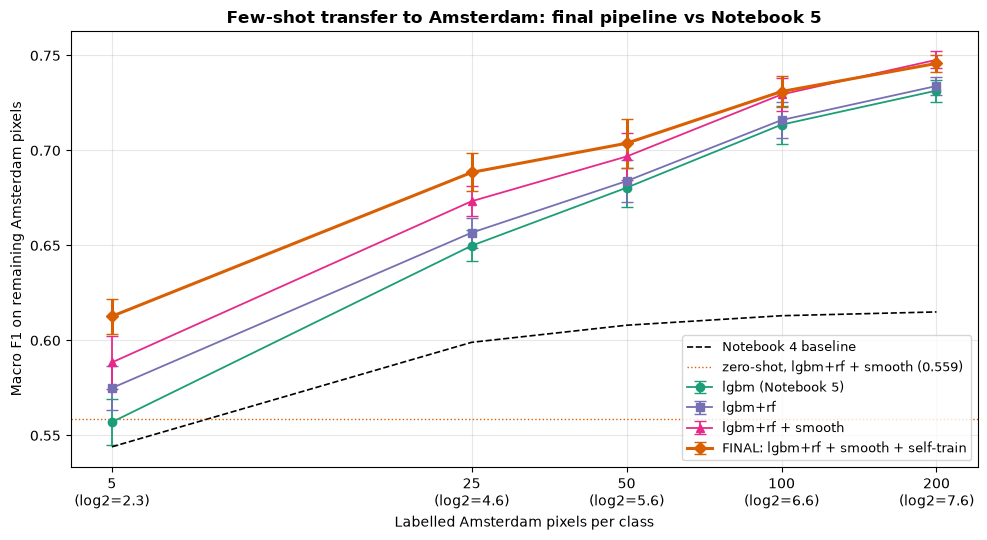

In [10]:
# Required submission plot: F1 (± std) against log2(sample size)
STYLE = {REF: ('#1b9e77', 'o'), 'lgbm+rf': ('#7570b3', 's'),
         'lgbm+rf + smooth': ('#e7298a', '^'), FINAL: ('#d95f02', 'D')}
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.log2(SHOTS)
for row, (col, mk) in STYLE.items():
    ax.errorbar(x, [np.mean(res[row][n]) for n in SHOTS], yerr=[np.std(res[row][n]) for n in SHOTS],
                fmt=mk + '-', color=col, capsize=4, lw=2.2 if row == FINAL else 1.3, label=row)
ax.plot(x, [BASELINE_NB4[n] for n in SHOTS], 'k--', lw=1.2, label='Notebook 4 baseline')
ax.axhline(ZERO_SHOT['lgbm+rf + smooth'], color='#d95f02', ls=':', lw=1,
           label=f"zero-shot, lgbm+rf + smooth ({ZERO_SHOT['lgbm+rf + smooth']:.3f})")
ax.set_xticks(x); ax.set_xticklabels([f'{n}\n(log2={np.log2(n):.1f})' for n in SHOTS])
ax.set_xlabel('Labelled Amsterdam pixels per class'); ax.set_ylabel('Macro F1 on remaining Amsterdam pixels')
ax.set_title('Few-shot transfer to Amsterdam: final pipeline vs Notebook 5', fontweight='bold')
ax.grid(alpha=.3); ax.legend(loc='lower right', fontsize=9)
plt.tight_layout(); plt.show()

Per-class F1, n = 25


,Class 1,Class 2,Class 3,Class 4
lgbm (Notebook 5),0.698,0.626,0.659,0.617
rf,0.647,0.619,0.649,0.578
lgbm+rf,0.702,0.641,0.668,0.616
lgbm + smooth,0.732,0.652,0.670,0.625
lgbm+rf + smooth,0.733,0.663,0.674,0.622
FINAL: lgbm+rf + smooth + self-train,0.751,0.677,0.685,0.641


Per-class F1, n = 200


,Class 1,Class 2,Class 3,Class 4
lgbm (Notebook 5),0.778,0.709,0.738,0.701
rf,0.753,0.692,0.704,0.617
lgbm+rf,0.784,0.718,0.741,0.693
lgbm + smooth,0.796,0.733,0.747,0.716
lgbm+rf + smooth,0.801,0.740,0.747,0.703
FINAL: lgbm+rf + smooth + self-train,0.799,0.740,0.744,0.700


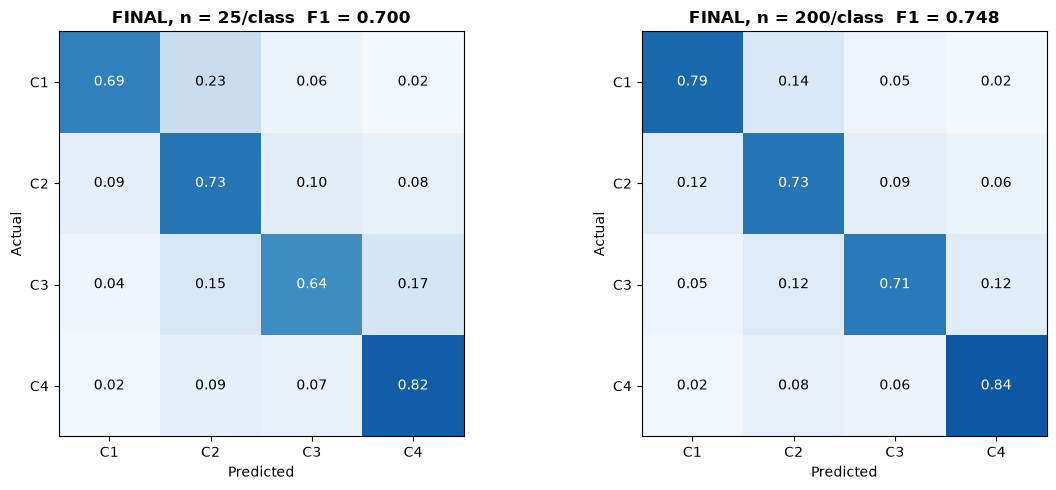

In [11]:
def plot_cm(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[1, 2, 3, 4]).astype(float)
    cm /= cm.sum(1, keepdims=True)
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='white' if cm[i, j] > .6 else 'black')
    ax.set_xticks(range(4)); ax.set_xticklabels([f'C{k}' for k in range(1, 5)])
    ax.set_yticks(range(4)); ax.set_yticklabels([f'C{k}' for k in range(1, 5)])
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(title, fontweight='bold')


# Per-class F1 (mean over draws) and confusion matrices of the final pipeline (first draw)
for n in (25, 200):
    pc = pd.DataFrame({r: np.mean(res_pc[r][n], 0) for r in ORDER},
                      index=[f'Class {k}' for k in range(1, 5)]).T.round(3)
    print(f'Per-class F1, n = {n}')
    display(pc)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, n in zip(axes, (25, 200)):
    sup = DRAWS[n][0]
    q = np.ones(len(ya), bool); q[sup] = False
    pred = run_pipeline(sup, n)[0][FINAL][q].argmax(1) + 1
    plot_cm(ax, ya[q], pred, f'FINAL, n = {n}/class  F1 = {f1_score(ya[q], pred, average="macro"):.3f}')
plt.tight_layout(); plt.show()

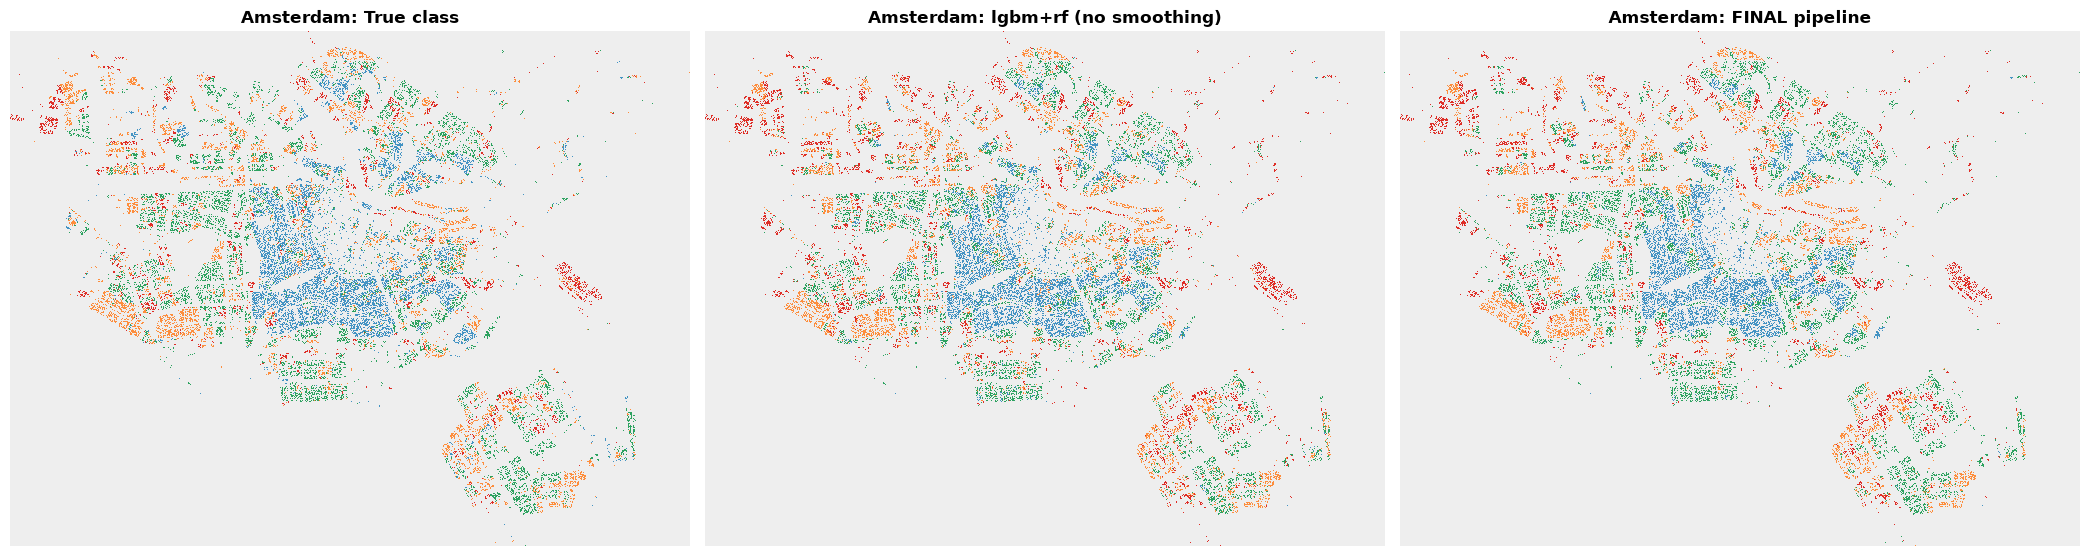

In [12]:
# Map: where does smoothing change the prediction? (first 25-shot draw)
sup = DRAWS[25][0]
o = run_pipeline(sup, 25)[0]
gx, gy, shape = GRID['Amsterdam']


def to_img(v):
    img = np.full(shape, np.nan, np.float32); img[gy, gx] = v
    return img[::-1]


from matplotlib.colors import ListedColormap
cmap = ListedColormap(['#4393c3', '#2ca25f', '#fd8d3c', '#de2d26']); cmap.set_bad('#eeeeee')
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, (title, v) in zip(axes, [('True class', ya),
                                 ('lgbm+rf (no smoothing)', o['lgbm+rf'].argmax(1) + 1),
                                 ('FINAL pipeline', o[FINAL].argmax(1) + 1)]):
    ax.imshow(to_img(v.astype(float)), cmap=cmap, vmin=.5, vmax=4.5, interpolation='nearest')
    ax.set_title(f'Amsterdam: {title}', fontweight='bold'); ax.axis('off')
plt.tight_layout(); plt.show()

## 7.6 Reusable transfer procedure

`adapt_final(n)` runs the whole final pipeline for one seeded draw of *n* labelled pixels per class and returns the predicted class of **every** Amsterdam pixel plus the held-out F1. The only inputs are the saved Madrid model, the city's unlabelled imagery features and *n* labels per class, so the same procedure applies to any new city: build its features with `build_features`, scale them with `city_scale`, and add its grid to `GRID`.

In [13]:
def adapt_final(n, seed=SEED):
    r = np.random.default_rng(seed)
    sup = np.concatenate([r.choice(np.where(ya == c)[0], n, replace=False) for c in range(1, 5)])
    q = np.ones(len(ya), bool); q[sup] = False
    pred = run_pipeline(sup, n)[0][FINAL].argmax(1) + 1
    return pred, f1_score(ya[q], pred[q], average='macro')


for n in SHOTS:
    pred, f1 = adapt_final(n)
    pd.DataFrame({'px': DATA['Amsterdam']['px'], 'py': DATA['Amsterdam']['py'], 'pred_class': pred}) \
      .to_csv(RESULTS_DIR / f'nb7_amsterdam_predictions_n{n}.csv', index=False)
    print(f'n = {n:3d}: held-out macro-F1 = {f1:.3f}  -> results/nb7_amsterdam_predictions_n{n}.csv')

n =   5: held-out macro-F1 = 0.607  -> results/nb7_amsterdam_predictions_n5.csv
n =  25: held-out macro-F1 = 0.671  -> results/nb7_amsterdam_predictions_n25.csv
n =  50: held-out macro-F1 = 0.702  -> results/nb7_amsterdam_predictions_n50.csv
n = 100: held-out macro-F1 = 0.724  -> results/nb7_amsterdam_predictions_n100.csv
n = 200: held-out macro-F1 = 0.741  -> results/nb7_amsterdam_predictions_n200.csv
